In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

TABLES_DIR = PROJECT_ROOT / "tables"
FIGURES_DIR = PROJECT_ROOT / "figures"

comparison_path = (
    TABLES_DIR / "final_test_model_comparison.csv"
)

final_results = pd.read_csv(comparison_path)

print("=" * 65)
print("FINAL RESEARCH RESULTS")
print("=" * 65)

print("Models evaluated:", len(final_results))

display(final_results)

FINAL RESEARCH RESULTS
Models evaluated: 7


,Rank,Model,RMSE,MAE,Safe_MAPE,RMSE_Improvement_Percent,MAE_Improvement_Percent
0,1,Linear Regression,0.017902,0.011252,29.809760,16.200963,12.045387
1,2,GARCH Expanding Window,0.019291,0.012415,33.890349,9.695768,2.957886
2,3,XGBoost,0.019411,0.011552,29.541793,9.135723,9.706591
3,4,Random Forest,0.019937,0.011745,29.580500,6.672351,8.194163
4,5,XGBoost + GPR (Provisional),0.020130,0.013150,35.965345,5.769073,-2.790180
5,6,Persistence,0.021363,0.012794,31.104661,0.000000,0.000000
6,7,LSTM,0.022243,0.015380,37.036409,-4.120764,-20.216880


In [2]:
# Create a formatted results table

publication_table = final_results[
    [
        "Rank",
        "Model",
        "RMSE",
        "MAE",
        "Safe_MAPE",
        "RMSE_Improvement_Percent"
    ]
].copy()

publication_table = publication_table.rename(
    columns={
        "Safe_MAPE": "Safe MAPE (%)",
        "RMSE_Improvement_Percent": "RMSE Improvement (%)"
    }
)

publication_table["RMSE"] = (
    publication_table["RMSE"].round(6)
)

publication_table["MAE"] = (
    publication_table["MAE"].round(6)
)

publication_table["Safe MAPE (%)"] = (
    publication_table["Safe MAPE (%)"].round(2)
)

publication_table["RMSE Improvement (%)"] = (
    publication_table["RMSE Improvement (%)"].round(2)
)

display(publication_table)

publication_table.to_csv(
    TABLES_DIR / "dissertation_final_model_comparison.csv",
    index=False
)

print("Dissertation comparison table saved!")

,Rank,Model,RMSE,MAE,Safe MAPE (%),RMSE Improvement (%)
0,1,Linear Regression,0.017902,0.011252,29.81,16.20
1,2,GARCH Expanding Window,0.019291,0.012415,33.89,9.70
2,3,XGBoost,0.019411,0.011552,29.54,9.14
3,4,Random Forest,0.019937,0.011745,29.58,6.67
4,5,XGBoost + GPR (Provisional),0.020130,0.013150,35.97,5.77
5,6,Persistence,0.021363,0.012794,31.10,0.00
6,7,LSTM,0.022243,0.015380,37.04,-4.12


Dissertation comparison table saved!


In [3]:
hac_results = pd.read_csv(
    TABLES_DIR / "hac_vs_persistence.csv"
)

gpr_results = pd.read_csv(
    TABLES_DIR / "hac_gpr_contribution.csv"
)

holm_results = pd.read_csv(
    TABLES_DIR / "hac_linear_regression_holm_corrected.csv"
)

print("HAC vs Persistence:")
display(hac_results)

print("\nGPR Contribution:")
display(gpr_results)

print("\nHolm-Corrected Comparisons:")
display(holm_results)

HAC vs Persistence:


,Model,Benchmark,Mean_Loss_Difference,HAC_SE,Test_Statistic,P_Value,CI_Lower,CI_Upper,Significant_5pct
0,Linear Regression,Persistence,-0.000136,0.000125,-1.082904,0.278851,-0.000382,0.000110,False
1,Random Forest,Persistence,-0.000059,0.000107,-0.548883,0.583086,-0.000269,0.000151,False
2,XGBoost,Persistence,-0.000080,0.000108,-0.737841,0.460611,-0.000291,0.000132,False
3,XGBoost + GPR (Provisional),Persistence,-0.000051,0.000114,-0.449995,0.652714,-0.000274,0.000172,False
4,GARCH Expanding Window,Persistence,-0.000084,0.000098,-0.856097,0.391944,-0.000277,0.000109,False
5,LSTM,Persistence,0.000038,0.000162,0.236941,0.812703,-0.000279,0.000356,False



GPR Contribution:


,Model_A,Model_B,Mean_Loss_Difference,HAC_SE,Test_Statistic,P_Value,CI_Lower,CI_Upper
0,XGBoost + GPR (Provisional),XGBoost,0.000028,0.000075,0.378895,0.704766,-0.000119,0.000176



Holm-Corrected Comparisons:


,Model_A,Model_B,Mean_Loss_Difference,HAC_SE,Test_Statistic,P_Value,CI_Lower,CI_Upper,Significant_5pct,Holm_Adjusted_P,Significant_After_Holm
0,Linear Regression,Persistence,-0.000136,0.000125,-1.082904,0.278851,-0.000382,0.000110,False,1.000000,False
1,Linear Regression,Random Forest,-0.000077,0.000069,-1.122630,0.261594,-0.000211,0.000057,False,1.000000,False
2,Linear Regression,XGBoost,-0.000056,0.000048,-1.169279,0.242291,-0.000151,0.000038,False,1.000000,False
3,Linear Regression,XGBoost + GPR (Provisional),-0.000085,0.000076,-1.113494,0.265496,-0.000234,0.000064,False,1.000000,False
4,Linear Regression,GARCH Expanding Window,-0.000052,0.000044,-1.177977,0.238806,-0.000138,0.000034,False,1.000000,False
5,Linear Regression,LSTM,-0.000174,0.000073,-2.388889,0.016899,-0.000317,-0.000031,True,0.101396,False


In [4]:
# ============================================================
# STATISTICAL SIGNIFICANCE SUMMARY
# ============================================================

significance_table = hac_results[
    [
        "Model",
        "Mean_Loss_Difference",
        "P_Value",
        "Significant_5pct"
    ]
].copy()

significance_table = significance_table.rename(
    columns={
        "Mean_Loss_Difference": "Mean Squared-Loss Difference",
        "P_Value": "HAC p-value",
        "Significant_5pct": "Significant at 5%"
    }
)

significance_table["Significant at 5%"] = (
    significance_table["Significant at 5%"]
    .map({True: "Yes", False: "No"})
)

significance_table["Mean Squared-Loss Difference"] = (
    significance_table["Mean Squared-Loss Difference"]
    .round(8)
)

significance_table["HAC p-value"] = (
    significance_table["HAC p-value"]
    .round(4)
)

display(significance_table)

significance_table.to_csv(
    TABLES_DIR / "dissertation_statistical_significance.csv",
    index=False
)

print("Statistical significance table saved!")

,Model,Mean Squared-Loss Difference,HAC p-value,Significant at 5%
0,Linear Regression,-0.000136,0.2789,No
1,Random Forest,-0.000059,0.5831,No
2,XGBoost,-0.000080,0.4606,No
3,XGBoost + GPR (Provisional),-0.000051,0.6527,No
4,GARCH Expanding Window,-0.000084,0.3919,No
5,LSTM,0.000038,0.8127,No


Statistical significance table saved!


In [5]:
# ============================================================
# GPR CONTRIBUTION SUMMARY
# ============================================================

market_rmse = final_results.loc[
    final_results["Model"] == "XGBoost",
    "RMSE"
].iloc[0]

gpr_rmse = final_results.loc[
    final_results["Model"] == "XGBoost + GPR (Provisional)",
    "RMSE"
].iloc[0]

rmse_change = (
    (gpr_rmse - market_rmse)
    / market_rmse
) * 100

gpr_p_value = gpr_results["P_Value"].iloc[0]

gpr_summary = pd.DataFrame({
    "Measure": [
        "Market-only XGBoost RMSE",
        "XGBoost + GPR RMSE",
        "RMSE Change (%)",
        "HAC p-value",
        "GPR SHAP Attribution Share (%)"
    ],
    "Value": [
        market_rmse,
        gpr_rmse,
        rmse_change,
        gpr_p_value,
        27.15
    ]
})

display(gpr_summary.round(6))

gpr_summary.to_csv(
    TABLES_DIR / "dissertation_gpr_contribution_summary.csv",
    index=False
)

print("GPR contribution summary saved!")

,Measure,Value
0,Market-only XGBoost RMSE,0.019411
1,XGBoost + GPR RMSE,0.020130
2,RMSE Change (%),3.705142
3,HAC p-value,0.704766
4,GPR SHAP Attribution Share (%),27.150000


GPR contribution summary saved!


In [6]:
# ============================================================
# SHAP FEATURE IMPORTANCE TABLES
# ============================================================

market_shap = pd.read_csv(
    TABLES_DIR / "shap_market_feature_importance.csv"
)

gpr_shap = pd.read_csv(
    TABLES_DIR / "shap_gpr_feature_importance.csv"
)

market_shap["Model"] = "Market-only XGBoost"

gpr_shap["Model"] = "XGBoost + GPR"

combined_shap = pd.concat(
    [market_shap, gpr_shap],
    ignore_index=True
)

combined_shap = combined_shap[
    [
        "Model",
        "Feature",
        "Mean_Absolute_SHAP"
    ]
]

display(combined_shap.round(6))

combined_shap.to_csv(
    TABLES_DIR / "dissertation_shap_feature_importance.csv",
    index=False
)

print("Combined SHAP table saved!")

,Model,Feature,Mean_Absolute_SHAP
0,Market-only XGBoost,RV_Historical_5D,0.003010
1,Market-only XGBoost,RV_Historical_20D,0.002825
2,Market-only XGBoost,RV_Historical_60D,0.002542
3,Market-only XGBoost,RV_Historical_10D,0.002289
4,Market-only XGBoost,Return_Lag1,0.001832
5,Market-only XGBoost,Absolute_Return,0.000861
6,Market-only XGBoost,RV_20D_Lag1,0.000678
7,XGBoost + GPR,GPR_MA20,0.004328
8,XGBoost + GPR,RV_Historical_20D,0.003242
9,XGBoost + GPR,RV_Historical_5D,0.003216


Combined SHAP table saved!


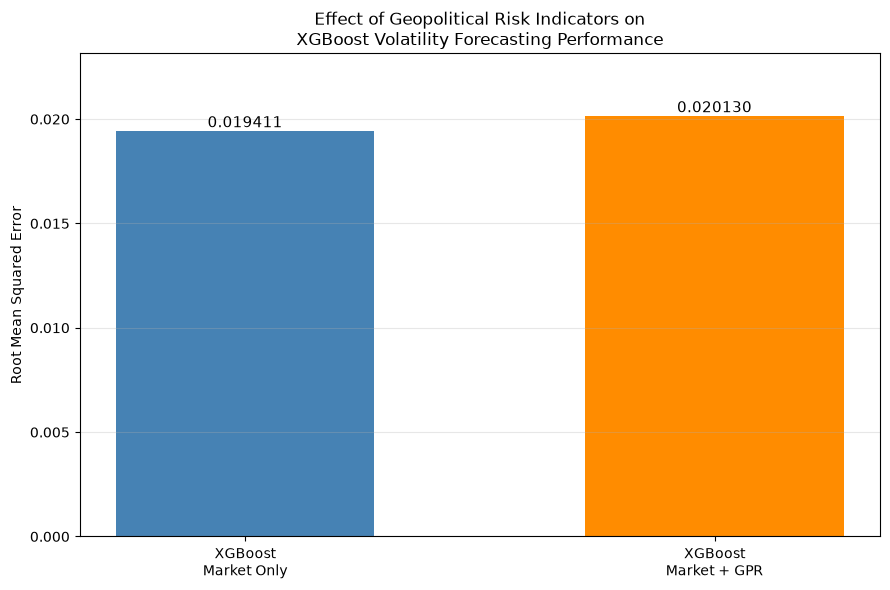

In [7]:
# ============================================================
# GPR MODEL COMPARISON FIGURE
# ============================================================

import matplotlib.pyplot as plt

models = [
    "XGBoost\nMarket Only",
    "XGBoost\nMarket + GPR"
]

rmse_values = [
    market_rmse,
    gpr_rmse
]

plt.figure(figsize=(9, 6))

bars = plt.bar(
    models,
    rmse_values,
    color=["steelblue", "darkorange"],
    width=0.55
)

for bar, value in zip(bars, rmse_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.0002,
        f"{value:.6f}",
        ha="center",
        fontsize=11
    )

plt.ylabel("Root Mean Squared Error")

plt.title(
    "Effect of Geopolitical Risk Indicators on\n"
    "XGBoost Volatility Forecasting Performance"
)

plt.ylim(0, max(rmse_values) * 1.15)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "dissertation_gpr_rmse_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

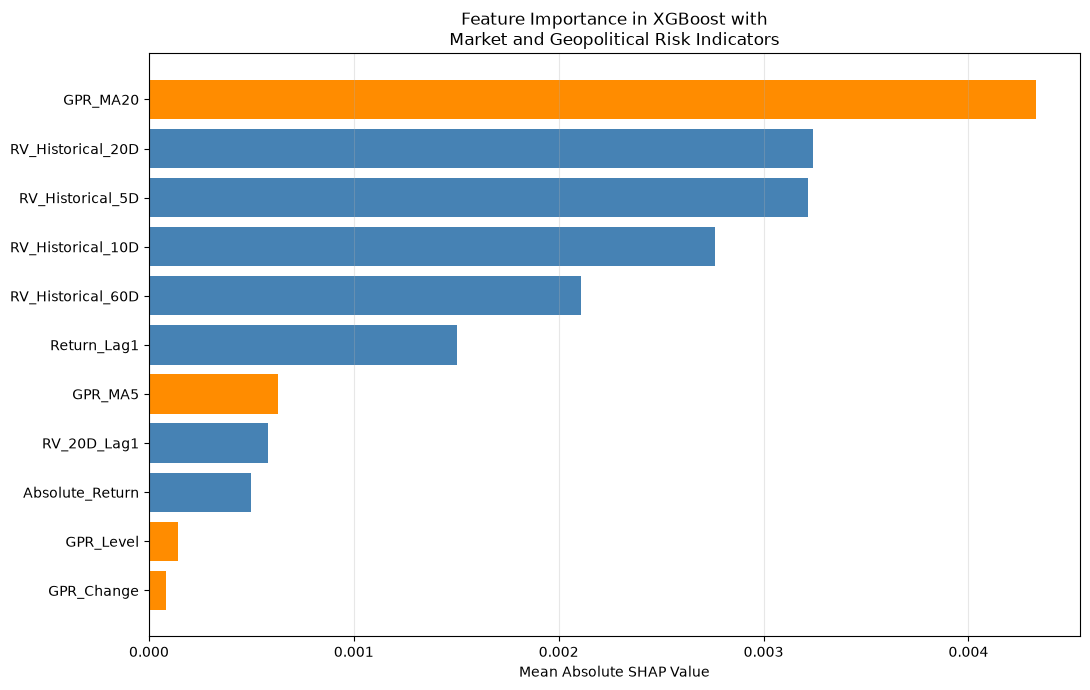

In [8]:
# ============================================================
# SHAP FEATURE IMPORTANCE FIGURE
# ============================================================

shap_plot_data = (
    gpr_shap
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=True
    )
)

colors = [
    "darkorange" if feature.startswith("GPR")
    else "steelblue"
    for feature in shap_plot_data["Feature"]
]

plt.figure(figsize=(11, 7))

plt.barh(
    shap_plot_data["Feature"],
    shap_plot_data["Mean_Absolute_SHAP"],
    color=colors
)

plt.xlabel("Mean Absolute SHAP Value")

plt.title(
    "Feature Importance in XGBoost with\n"
    "Market and Geopolitical Risk Indicators"
)

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "dissertation_gpr_shap_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
# ============================================================
# VERIFY DISSERTATION OUTPUTS
# ============================================================

required_tables = [
    "dissertation_final_model_comparison.csv",
    "dissertation_statistical_significance.csv",
    "dissertation_gpr_contribution_summary.csv",
    "dissertation_shap_feature_importance.csv"
]

required_figures = [
    "final_test_rmse_comparison.png",
    "final_test_actual_vs_predicted.png",
    "final_test_absolute_errors.png",
    "dissertation_gpr_rmse_comparison.png",
    "dissertation_gpr_shap_importance.png"
]

print("=" * 65)
print("DISSERTATION OUTPUT VERIFICATION")
print("=" * 65)

all_files_present = True

for filename in required_tables:

    file_path = TABLES_DIR / filename
    exists = file_path.exists()

    print(
        f"{'OK' if exists else 'MISSING'} — {filename}"
    )

    if not exists:
        all_files_present = False

for filename in required_figures:

    file_path = FIGURES_DIR / filename
    exists = file_path.exists()

    print(
        f"{'OK' if exists else 'MISSING'} — {filename}"
    )

    if not exists:
        all_files_present = False

print("\n" + "=" * 65)

if all_files_present:
    print("ALL REQUIRED DISSERTATION OUTPUTS VERIFIED!")
else:
    print("Some outputs are missing. Review the list above.")

DISSERTATION OUTPUT VERIFICATION
OK — dissertation_final_model_comparison.csv
OK — dissertation_statistical_significance.csv
OK — dissertation_gpr_contribution_summary.csv
OK — dissertation_shap_feature_importance.csv
OK — final_test_rmse_comparison.png
OK — final_test_actual_vs_predicted.png
OK — final_test_absolute_errors.png
OK — dissertation_gpr_rmse_comparison.png
OK — dissertation_gpr_shap_importance.png

ALL REQUIRED DISSERTATION OUTPUTS VERIFIED!
